In [4]:
import pandas as pd
import matplotlib.pyplot as plt
file_list = ["equally_prevalent.csv", "more_prev_in_dreams_covid.csv", "more_prev_in_twitter_covid.csv"]

df = pd.concat(
    (pd.read_csv(f"./data/{filename}") for filename in file_list),
    ignore_index=True,
)[["sym", "rank_twitter_covid", "rank_dreams_covid"]]
df.head()

,sym,rank_twitter_covid,rank_dreams_covid
0,coronavirus,0,1
1,flu,2,27
2,corona virus,5,9
3,cough,10,5
4,virus,11,0


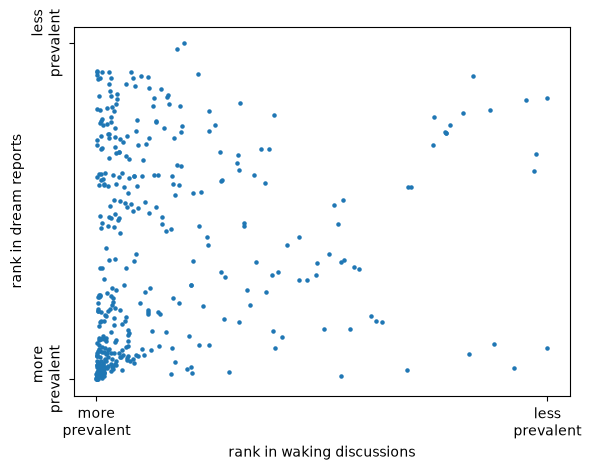

In [31]:
x = df["rank_twitter_covid"]
y = df["rank_dreams_covid"]

plt.scatter(x, y, s=5)
plt.xlabel("rank in waking discussions")
plt.ylabel("rank in dream reports")

plt.xticks([x.min(), x.max()], ["more\nprevalent", "less\nprevalent"])
plt.yticks([y.min(), y.max()], ["more\nprevalent", "less\nprevalent"],rotation=90, va="center")

plt.show()

y = 0.020548568922270572x + 547.1579809476208   R² = 0.03483927655687924


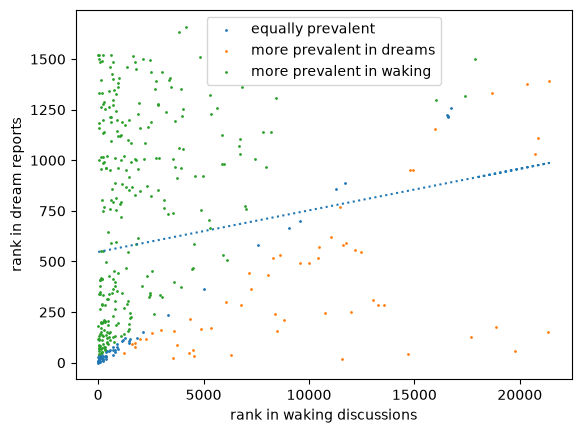

In [34]:
from sklearn.linear_model import LinearRegression

X = df[["rank_twitter_covid"]]
y = df["rank_dreams_covid"]

model = LinearRegression().fit(X, y)
print(f"y = {model.coef_[0]}x + {model.intercept_}   R² = {model.score(X, y)}")

labels = ["equally prevalent", "more prevalent in dreams", "more prevalent in waking"]  # same order as file_list
for filename, label in zip(file_list, labels):
    d = pd.read_csv(f"./data/{filename}")
    plt.scatter(d["rank_twitter_covid"], d["rank_dreams_covid"], s=1, label=label)
plt.plot(X, model.predict(X), linestyle=":")
plt.legend()
plt.xlabel("rank in waking discussions")
plt.ylabel("rank in dream reports")
plt.show()